# 2단계 — 이 고객을 왜 위험하다고 예측했을까?

**진행:** 동일 입력 확인 → Train/Test → 분류 모델 학습 → 예측 → 한 고객 SHAP → 전체 요약 → 승인·거절 사례 → Dependence → 군집별 설명.

`analysis_clustering.ipynb`를 먼저 실행한다. 데이터와 입력 순서가 같은 군집 결과만 사용한다. 분류와 SHAP은 원본 6개 변수에 적용하며, 군집 번호를 분류 입력에 추가하지 않는다. SHAP은 모델의 예측을 분해하는 설명이고 실제 원인이나 대출 정책의 정당성을 입증하지 않는다.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = None
for candidate in [Path.cwd()] + list(Path.cwd().parents):
    if (candidate / "src" / "analysis_clustering.py").is_file():
        project_root = candidate
        break
if project_root is None:
    raise FileNotFoundError("A5-2 또는 notebooks 폴더에서 실행하세요.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import limit_threads
limit_threads(2)
pd.set_option("display.precision", 4)
RANDOM_STATE = 42
feature_columns = ["age", "annual_income", "spending_score", "debt_ratio",
                   "credit_card_count", "overdue_count_6m"]
learning_dir = project_root / "results" / "learning"
figure_dir = learning_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
data_path = project_root / "finance_data.csv"
if not data_path.exists():
    raise FileNotFoundError("finance_data.csv가 없습니다. A5-1과 동일한 제공 데이터를 준비하세요.")
customers = pd.read_csv(data_path)
X = customers[feature_columns].copy()
data_fingerprint = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert customers.shape == (10000, 8)
assert set(["credit_score", "is_overdue"]).isdisjoint(X.columns)
print("고객 수:", len(customers), "/ 입력 변수 수:", X.shape[1])
print("결측치 수:", X.isna().sum().sum())
display(X.head())

고객 수: 10000 / 입력 변수 수: 6
결측치 수: 0


,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m
0,50,3406.0,54,0.29,1,1
1,25,2161.0,7,0.78,2,0
2,56,6390.0,83,0.88,9,2
3,54,2821.0,10,0.01,2,2
4,50,4925.0,90,0.06,7,1


## 1. 앞서 만든 군집 결과 확인

저장된 데이터 해시와 변수 순서를 확인한다. 이전 데이터의 군집 결과를 새 고객에 잘못 연결하지 않기 위한 조건이다. `.npz`에는 숫자 배열만 저장했으며 pickle 객체를 읽지 않는다.

In [2]:
metadata_path = learning_dir / "clustering_metadata.json"
arrays_path = learning_dir / "clustering.npz"
if not metadata_path.exists() or not arrays_path.exists():
    raise FileNotFoundError("먼저 analysis_clustering.ipynb를 처음부터 실행하세요.")
cluster_metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
if cluster_metadata["data_sha256"] != data_fingerprint or cluster_metadata["features"] != feature_columns:
    raise ValueError("데이터 또는 변수 순서가 다릅니다. 군집화 노트북을 다시 실행하세요.")
with np.load(arrays_path, allow_pickle=False) as saved_arrays:
    cluster_labels_all = saved_arrays["labels"].copy()
    cluster_centers = saved_arrays["centers"].copy()
    cluster_scaler_mean = saved_arrays["scaler_mean"].copy()
    cluster_scaler_scale = saved_arrays["scaler_scale"].copy()
selected_k = cluster_metadata["selected_k"]
assert len(cluster_labels_all) == len(customers)
assert cluster_centers.shape == (selected_k, len(feature_columns))
print("군집 수:", selected_k)

군집 수: 6


## 2. 분류는 Train에서 학습하고 Test에서 평가

현재 고객 집단 전체를 기술한 군집화와 달리, 분류는 입력으로 연체 여부를 예측하는 지도학습이다. A5-1과 같은 8:2 층화 분할, seed 42를 사용한다. 원본 데이터의 결측치가 없고, RF는 거리를 기준으로 학습하지 않으므로 표준화하지 않는다. SHAP도 원래 단위로 읽을 수 있다.

In [3]:
from sklearn.model_selection import train_test_split

y = customers["is_overdue"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE,
)
print("Train/Test:", X_train.shape, X_test.shape)
print("Train/Test 연체 비율:", y_train.mean(), y_test.mean())
assert set(X_train.index).isdisjoint(X_test.index)

Train/Test: (8000, 6) (2000, 6)
Train/Test 연체 비율: 0.120125 0.12


## 3. Random Forest를 직접 만들고 학습

설정은 A5-1에서 이어온 RF의 400개 나무, 깊이 12, 리프 최소 1, class_weight=balanced다. 입력은 원본 6개로 맞춘다. 앞 미션의 파생 입력을 포함한 모델과는 동일한 객체가 아니라, 같은 설정으로 다시 학습하는 모델이다.

In [4]:
from sklearn.ensemble import RandomForestClassifier

risk_model = RandomForestClassifier(
    n_estimators=400, max_depth=12, min_samples_leaf=1,
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=2,
)
risk_model.fit(X_train, y_train)
print("클래스 순서:", risk_model.classes_)
print("학습한 입력 수:", risk_model.n_features_in_)

클래스 순서: [0 1]
학습한 입력 수: 6


## 4. 연체 점수와 0/1 예측 구분

`predict_proba`는 고객×클래스 배열이다. 클래스 순서를 확인하고 클래스 1의 열을 선택한다. 0.5 이상을 위험 판정으로 본다. 가중치 학습 모델의 출력은 보정 검증 없이 실제 연체율과 같다고 간주하지 않는다.

In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

probabilities_by_class = risk_model.predict_proba(X_test)
overdue_class_index = int(np.flatnonzero(risk_model.classes_ == 1)[0])
overdue_probabilities = probabilities_by_class[:, overdue_class_index]
predicted_labels = (overdue_probabilities >= 0.5).astype(int)
metrics = {
    "accuracy": accuracy_score(y_test, predicted_labels),
    "precision": precision_score(y_test, predicted_labels),
    "recall": recall_score(y_test, predicted_labels),
    "f1": f1_score(y_test, predicted_labels),
    "roc_auc": roc_auc_score(y_test, overdue_probabilities),
}
display(pd.Series(metrics))
display(pd.DataFrame({"actual": y_test.iloc[:5], "score": overdue_probabilities[:5],
                      "prediction": predicted_labels[:5]}))

accuracy     0.8950
precision    0.5429
recall       0.7917
f1           0.6441
roc_auc      0.9404
dtype: float64

,actual,score,prediction
5911,1,0.2684,0
3120,0,0.1092,0
8838,0,0.0751,0
8399,0,0.0058,0
6896,1,0.9459,1


## 5. 한 고객의 점수를 SHAP으로 분해

SHAP이 설명하는 대상은 이 RF의 **연체 클래스 점수**다. TreeExplainer에 배경 표본을 따로 넘기지 않아 트리에 기록된 학습 경로를 기준으로 설명한다. 기준값은 그 설명 방식의 기대 출력이며 실제 연체율 12%나 지금 Test 평균과 같다고 가정하지 않는다. 라이브러리의 첫 계산 결과는 고객×변수×클래스 구조다.

In [6]:
warnings.filterwarnings("ignore", message="IProgress not found.*")
import shap

tree_explainer = shap.TreeExplainer(risk_model)
all_class_explanations = tree_explainer(X_test)
print("SHAP 전체 shape:", all_class_explanations.values.shape)
assert all_class_explanations.values.shape == (len(X_test), len(feature_columns), len(risk_model.classes_))
overdue_explanation = all_class_explanations[:, :, overdue_class_index]
print("연체 클래스만 선택:", overdue_explanation.values.shape)

SHAP 전체 shape: (2000, 6, 2)
연체 클래스만 선택: (2000, 6)


In [7]:
first_position = 0
first_contributions = overdue_explanation.values[first_position]
first_base_value = float(overdue_explanation.base_values[first_position])
first_model_score = float(overdue_probabilities[first_position])
display(pd.DataFrame({"feature": feature_columns, "input_value": X_test.iloc[first_position].to_numpy(),
                      "contribution": first_contributions}))
print("기준값:", first_base_value)
print("기여 합:", first_contributions.sum())
print("기준값 + 기여 합:", first_base_value + first_contributions.sum())
print("모델 점수:", first_model_score)
reconstructed_scores = overdue_explanation.base_values + overdue_explanation.values.sum(axis=1)
np.testing.assert_allclose(reconstructed_scores, overdue_probabilities, atol=1e-6, rtol=0)
print("Test 전체 SHAP 재구성 최대 오차:", np.abs(reconstructed_scores - overdue_probabilities).max())

,feature,input_value,contribution
0,age,51.00,-1.1279e-02
1,annual_income,3559.00,-5.7104e-02
2,spending_score,52.00,9.6198e-05
3,debt_ratio,0.84,1.1988e-01
4,credit_card_count,1.00,-6.7702e-03
5,overdue_count_6m,0.00,-2.7626e-01


기준값: 0.49979437500000023
기여 합: -0.23143831785255375
기준값 + 기여 합: 0.2683560571474465
모델 점수: 0.2683560571474422
Test 전체 SHAP 재구성 최대 오차: 2.120525977034049e-14


**출력 읽기:** 양수는 기준값보다 점수를 올리는 방향, 음수는 낮추는 방향이다. 점수 0.10의 변화는 10퍼센트포인트다. 값이 높으면 항상 양수가 되는 것은 아니며 모델의 관계에 달려 있다.

**확인 질문:** 한 고객의 가장 큰 기여 변수가 전체 고객에서도 반드시 1위일까?
<details><summary>답 확인</summary>아니다. Local은 그 고객의 기여다. Global은 여러 고객의 영향 크기를 요약한다. 서로 다른 질문이다.</details>

## 6. 여러 고객을 요약 — Global SHAP

고객별 절댓값 기여를 평균내면 방향이 상쇄되지 않는 영향 크기를 얻는다. Summary Plot에서는 점 하나가 고객 하나이며 색은 해당 입력값의 높고 낮음을 나타낸다.

,feature,mean_absolute_shap
1,annual_income,0.2434
5,overdue_count_6m,0.1513
3,debt_ratio,0.1195
2,spending_score,0.0185
0,age,0.0157
4,credit_card_count,0.0095


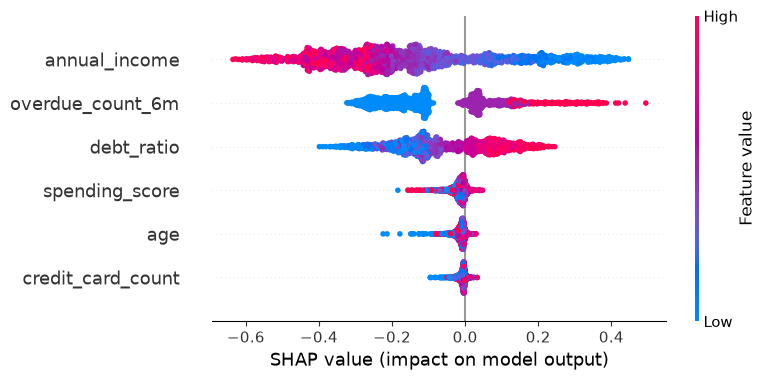

In [8]:
importance_rows = []
for feature_index, feature_name in enumerate(feature_columns):
    contributions = overdue_explanation.values[:, feature_index]
    importance_rows.append({"feature": feature_name,
                            "mean_absolute_shap": np.abs(contributions).mean()})
importance_table = pd.DataFrame(importance_rows).sort_values("mean_absolute_shap", ascending=False)
display(importance_table)
shap.plots.beeswarm(overdue_explanation, max_display=6, show=False)
plt.tight_layout()
plt.savefig(figure_dir / "03_shap_summary.png", dpi=140, bbox_inches="tight")
plt.show()

전체 중요도는 **Test 2,000명의 설명**을 요약한 것이며 모든 미래 고객에 대한 불변 순위가 아니다. 소득·연체 이력·부채 비율의 방향을 그림에서 확인하고 생성 구조와 비교한다. 원인 효과나 개인의 책임으로 해석하지 않는다.

## 7. 승인·보류·거절 기준과 대표 고객

거절은 점수 0.5 이상, 승인 기준은 Train OOF에서 연체자의 95%를 보류 이상으로 보내도록 정한다. Test로 기준을 고르지 않는다. 이 절차는 비용 최적화나 확률 보정을 대신하지 않는다.

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve
from sklearn.base import clone

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_probabilities = cross_val_predict(clone(risk_model), X_train, y_train,
                                      cv=cv, method="predict_proba", n_jobs=1)[:, overdue_class_index]
_, oof_recall, oof_thresholds = precision_recall_curve(y_train, oof_probabilities)
meets_target = oof_recall[:-1] >= 0.95
hold_threshold = min(float(oof_thresholds[meets_target].max()), 0.5)
print("승인: 점수 <", hold_threshold, "/ 거절: 점수 >= 0.5")

승인: 점수 < 0.1777661263856251 / 거절: 점수 >= 0.5


같은 고객의 군집 번호와 예측 점수를 연결한다. 먼저 군집별 중심에 가장 가까운 Test 고객을 대표로 고른다. 가까움은 앞의 6차원 표준화 공간에서 측정한다. PCA 그림에서의 가까움으로 바꾸지 않는다.

In [10]:
test_cluster_ids = cluster_labels_all[X_test.index.to_numpy()]
Z_test = (X_test.to_numpy() - cluster_scaler_mean) / cluster_scaler_scale
distance_to_own_center = np.linalg.norm(Z_test - cluster_centers[test_cluster_ids], axis=1)
representative_rows = []
for cluster_id in range(selected_k):
    positions = np.flatnonzero(test_cluster_ids == cluster_id)
    if len(positions):
        closest_position = int(positions[np.argmin(distance_to_own_center[positions])])
        representative_rows.append({"cluster": cluster_id, "test_position": closest_position,
                                     "customer_index": int(X_test.index[closest_position]),
                                     "score": overdue_probabilities[closest_position]})
display(pd.DataFrame(representative_rows))
nearest_clusters = []
for customer_point in Z_test:
    distances = np.linalg.norm(cluster_centers - customer_point, axis=1)
    nearest_clusters.append(int(np.argmin(distances)))
np.testing.assert_array_equal(nearest_clusters, test_cluster_ids)

,cluster,test_position,customer_index,score
0,0,1882,861,0.4985
1,1,1621,1205,0.0057
2,2,1381,1217,0.0083
3,3,722,8586,0.0005
4,4,1094,2973,0.0079
5,5,1448,8169,0.0423


### 7-1. 승인과 거절을 각각 한 건 설명

거절 조건을 만족하는 Test 고객, 승인 조건을 만족하는 Test 고객 중 자기 군집 중심에 가장 가까운 고객을 고른다. 정답 라벨로 맞힌 사례만 골라내지 않는다. 승인·거절은 모델 점수 기준이며 실제 정상·연체 정답과 다를 수 있다.

reject / 고객: 6945 / 군집: 0 / 점수: 0.8665 / 실제 연체: 0


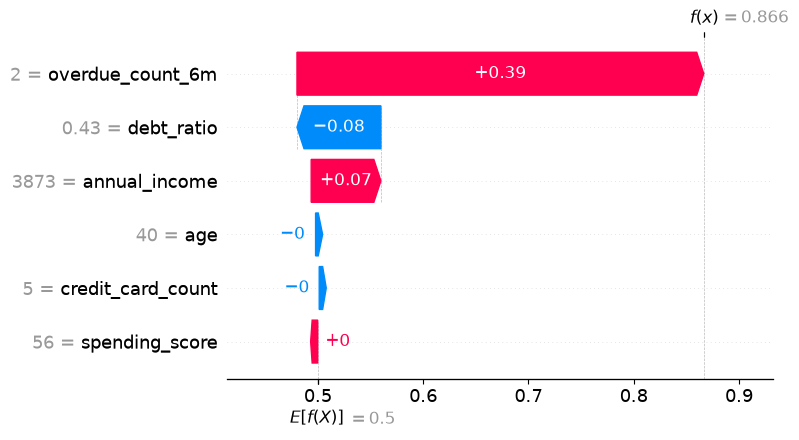

approve / 고객: 1217 / 군집: 2 / 점수: 0.0083 / 실제 연체: 0


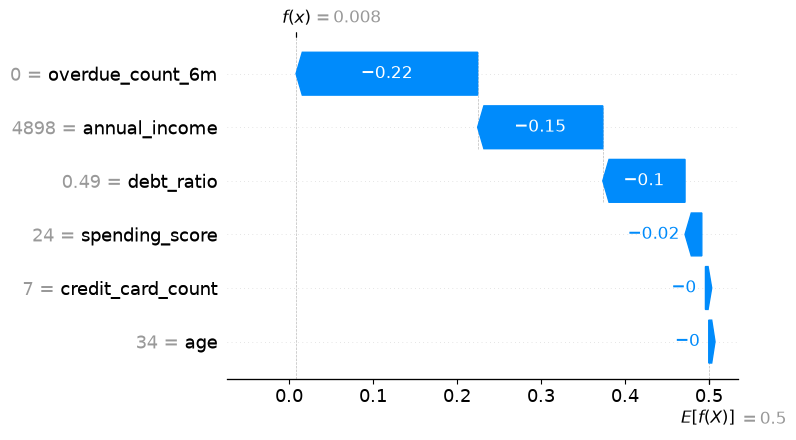

In [11]:
reject_positions = np.flatnonzero(overdue_probabilities >= 0.5)
approve_positions = np.flatnonzero(overdue_probabilities < hold_threshold)
if not len(reject_positions) or not len(approve_positions):
    raise ValueError("승인 또는 거절 조건에 맞는 고객이 없습니다. 점수 분포를 확인하세요.")
reject_position = int(reject_positions[np.argmin(distance_to_own_center[reject_positions])])
approve_position = int(approve_positions[np.argmin(distance_to_own_center[approve_positions])])
case_positions = [("reject", reject_position), ("approve", approve_position)]
for case_name, test_position in case_positions:
    print(case_name, "/ 고객:", X_test.index[test_position],
          "/ 군집:", test_cluster_ids[test_position],
          "/ 점수:", round(overdue_probabilities[test_position], 4),
          "/ 실제 연체:", y_test.iloc[test_position])
    shap.plots.waterfall(overdue_explanation[test_position], max_display=7, show=False)
    plt.tight_layout()
    plt.savefig(figure_dir / f"04_waterfall_{case_name}.png", dpi=140, bbox_inches="tight")
    plt.show()

In [12]:
for case_name, test_position in case_positions:
    contributions = overdue_explanation.values[test_position]
    sorted_indices = np.argsort(np.abs(contributions))[::-1]
    print(case_name, "— 기준 점수", round(float(overdue_explanation.base_values[test_position]), 3),
          "→ 이 고객 점수", round(float(overdue_probabilities[test_position]), 3))
    for feature_index in sorted_indices[:3]:
        feature_name = feature_columns[feature_index]
        input_value = X_test.iloc[test_position, feature_index]
        change = contributions[feature_index] * 100
        direction = "올리는" if change >= 0 else "낮추는"
        print(f"  {feature_name}={input_value:g}: 점수를 {abs(change):.1f}%p {direction} 방향의 기여")

reject — 기준 점수 0.5 → 이 고객 점수 0.866
  overdue_count_6m=2: 점수를 38.6%p 올리는 방향의 기여
  debt_ratio=0.43: 점수를 8.0%p 낮추는 방향의 기여
  annual_income=3873: 점수를 6.6%p 올리는 방향의 기여
approve — 기준 점수 0.5 → 이 고객 점수 0.008
  overdue_count_6m=0: 점수를 21.6%p 낮추는 방향의 기여
  annual_income=4898: 점수를 14.9%p 낮추는 방향의 기여
  debt_ratio=0.49: 점수를 9.8%p 낮추는 방향의 기여


## 8. Dependence — 입력값과 설명값의 관계

전체 중요도 상위 두 변수와 부채 비율을 본다. 중복이면 다음 순위로 보충한다. 가로축은 입력, 세로축은 그 변수의 기여이며 예측 점수 자체가 아니다. 다른 입력이 다르면 같은 가로축 값에서도 기여가 다를 수 있다.

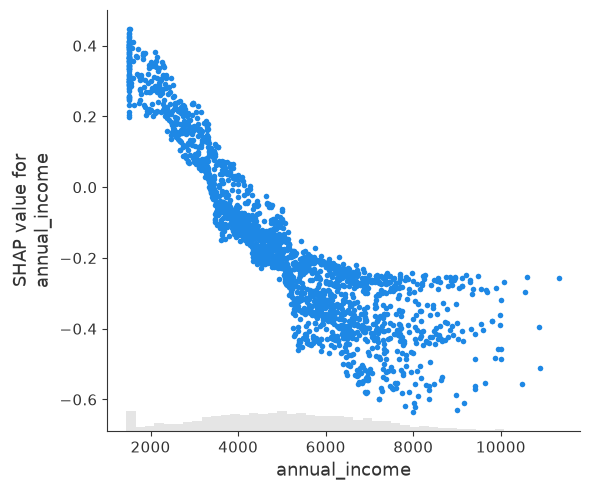

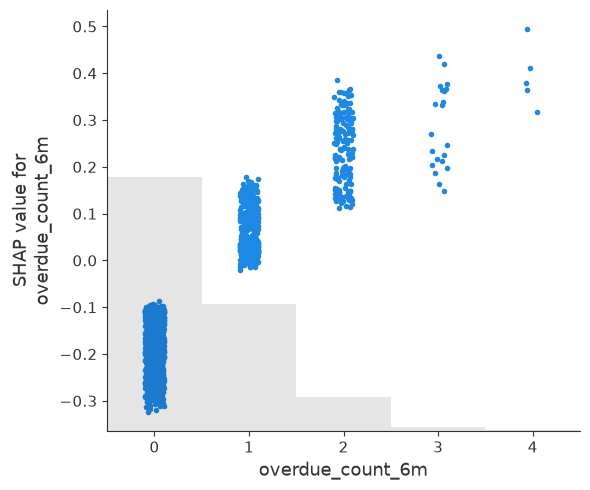

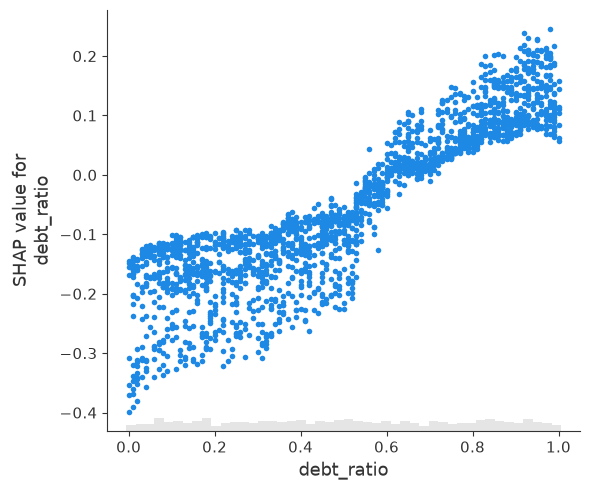

확인한 변수: ['annual_income', 'overdue_count_6m', 'debt_ratio']


In [13]:
dependence_features = importance_table["feature"].head(2).tolist()
if "debt_ratio" not in dependence_features:
    dependence_features.append("debt_ratio")
for feature_name in importance_table["feature"]:
    if len(dependence_features) == 3:
        break
    if feature_name not in dependence_features:
        dependence_features.append(feature_name)

for feature_name in dependence_features:
    shap.plots.scatter(overdue_explanation[:, feature_name], show=False)
    plt.tight_layout()
    plt.savefig(figure_dir / f"05_dependence_{feature_name}.png", dpi=140, bbox_inches="tight")
    plt.show()
print("확인한 변수:", dependence_features)

**해석 연습:** 소득이 높을 때 소득 기여가 위험 점수를 낮추는 방향인지 확인한다. 같은 소득의 점들이 퍼져 있으면 다른 입력과 모델의 조건부 관계도 작용할 수 있다. 연체 이력과 부채 비율도 입력값이 커질 때의 방향을 그림에서 확인한다. 고객의 소득만 바꾸면 실제 연체가 줄어든다는 인과 결론은 여기서 얻을 수 없다.

## 9. 군집 특징과 모델 근거를 함께 보기

군집별 Test 고객의 평균 예측 점수와 평균 SHAP을 비교한다. 군집의 평균 특징이 개인에게 모두 해당하지는 않는다. 같은 군집 안에서도 개별 점수와 기여가 다르므로 일괄 거절이나 마케팅 기준으로 바로 쓰지 않는다.

,test_customers,mean_score,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m
cluster,,,,,,,,
0,188,0.4780,-0.0213,-0.1541,-0.0200,-0.0605,-0.0106,0.2447
1,358,0.2054,-0.0161,-0.1948,-0.0132,0.0426,-0.0125,-0.1004
2,386,0.1251,-0.0166,-0.1673,-0.0174,-0.0708,-0.0058,-0.0967
3,378,0.0635,-0.0109,-0.1343,-0.0154,-0.1633,-0.0059,-0.1065
4,339,0.1184,-0.0113,-0.1263,-0.0174,-0.1053,-0.0099,-0.1112
5,351,0.2680,-0.0158,-0.1283,-0.0176,0.0403,-0.0074,-0.1030


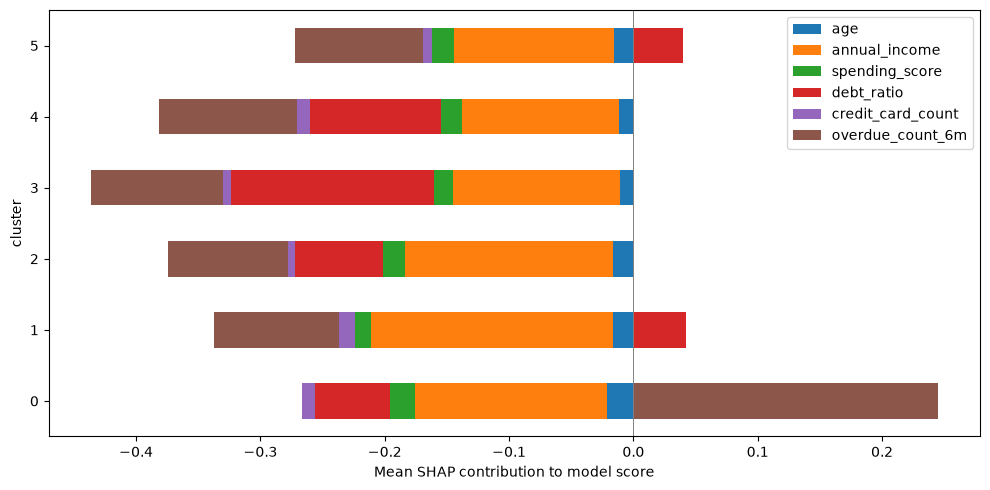

In [14]:
cluster_explanation_rows = []
for cluster_id in range(selected_k):
    member_mask = test_cluster_ids == cluster_id
    if not member_mask.any():
        continue
    row = {"cluster": cluster_id, "test_customers": int(member_mask.sum()),
           "mean_score": float(overdue_probabilities[member_mask].mean())}
    for feature_index, feature_name in enumerate(feature_columns):
        row[feature_name] = float(overdue_explanation.values[member_mask, feature_index].mean())
    cluster_explanation_rows.append(row)
cluster_explanation_table = pd.DataFrame(cluster_explanation_rows).set_index("cluster")
display(cluster_explanation_table)
cluster_explanation_table[feature_columns].plot.barh(stacked=True, figsize=(10, 5))
plt.axvline(0, color="gray", linewidth=0.7)
plt.xlabel("Mean SHAP contribution to model score")
plt.tight_layout()
plt.savefig(figure_dir / "06_cluster_shap.png", dpi=140, bbox_inches="tight")
plt.show()
cluster_explanation_table.to_csv(learning_dir / "cluster_shap.csv")

## 10. 공통 함수와 연결해서 검증

앞에서 펼친 계산을 기존 모듈에서 어떻게 재사용하는지 확인한다. SHAP의 가법성, 모델 설정, Train/Test 분할을 대조한다. 기존 보고서는 군집 번호를 연체율 순으로 다시 붙이고 다른 대표 사례 선정 규칙을 사용하므로 사례 번호와 군집 번호를 그대로 섞지 않는다.

In [15]:
from src import explain
from src import model as model_module
from src.data import split_data

module_split = split_data(customers)
np.testing.assert_array_equal(module_split.X_test.index, X_test.index)
assert risk_model.get_params() == model_module.build_model().get_params()
assert explain.additivity_error(overdue_explanation, overdue_probabilities) < 1e-6
module_importance = explain.global_importance(overdue_explanation)
module_features = []
for row in module_importance:
    module_features.append(row["feature"])
assert module_features == importance_table["feature"].tolist()
print("기존 모듈과 분할·모델 설정·SHAP 요약 일치")

기존 모듈과 분할·모델 설정·SHAP 요약 일치


## 11. 정리

군집화는 고객의 입력 차이를 묶고, 분류는 연체 여부를 예측하며, SHAP은 특정 모델 점수의 기여를 설명한다. PCA는 그림의 축이고 원래 입력 변수가 아니다. Global과 Local은 서로 다른 범위의 질문이다.

다음 질문에 결과를 가리키며 답해 본다: 군집 특징과 개별 판단 근거는 언제 다른가? 높은 SHAP 중요도가 고객 위험의 원인임을 뜻하는가? 낮은 Silhouette에서도 페르소나를 사용한다면 어떤 검증과 한계 설명이 필요한가?

그림과 표는 `results/learning/`에 저장된다. 기존 최종 보고서와 대시보드 자료는 그대로 유지된다. 알고리즘 비교와 Streamlit은 기본 흐름을 이해한 뒤 기존 CLI·앱에서 이어갈 수 있다.